# Analyse non supervisée des témoignages de symptômes

## Objectif

Ce notebook analyse un jeu de données de **témoignages de patients** décrivant leurs symptômes (en anglais), chacun associé à une couleur (voir section 4 pour l'usage de cette colonne).

On utilise des techniques de **NLP** (traitement du langage) et de **clustering non supervisé** pour regrouper automatiquement les témoignages qui parlent de symptômes similaires, sans connaître les catégories à l'avance.

**Outils utilisés** : uniquement `pandas`, `numpy`, `matplotlib` et `scikit-learn`, conformément aux outils autorisés pour ce projet. Une approche alternative utilisant des librairies hors de cette liste (embeddings de phrases via `sentence-transformers`) est présentée séparément dans `bonus/`, avec ses propres résultats.

### Plan
1. Chargement et nettoyage des données
2. Prétraitement du texte et vectorisation (TF-IDF)
3. Clustering avec K-Means et fonction de perte (inertie)
4. Recherche du nombre optimal de clusters (coude + silhouette)
5. Visualisation et mots-clés par cluster
6. Comparaison de modèles pour améliorer la précision
7. Modèle final retenu et conclusion

---

## 1. Premier aperçu des données brutes

On commence par un chargement rapide et naïf du fichier CSV, afin d'observer la structure brute des données.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Charger le CSV en précisant qu'il faut ignorer les virgules dans les guillemets
df = pd.read_csv('../data/Student_Dataset.csv', header=None, engine='python', on_bad_lines='skip')

print("Dimensions du fichier :", df.shape)
df.head()

Dimensions du fichier : (397, 2)


,0,1
0,1,On uneven paths the heel feels wobbly side‑to‑...
1,4,A short sprint brought on a twinge in the midd...
2,6,A sudden twist while reaching for a bag made o...
3,8,I noticed a rash on my forearms after handling...
4,11,I feel an unexplained pressure behind my eyes ...


**Problème constaté** : le fichier contient parfois 2 colonnes (id, texte), parfois 3 (id, couleur, texte), et des virgules à l'intérieur même des témoignages. Un simple `read_csv` ne suffit pas à tout charger correctement.

## 2. Chargement et nettoyage propre du fichier

On relit le fichier ligne par ligne avec le module `csv` (bibliothèque standard Python), en gérant nous-mêmes les deux formats possibles :
- si la ligne a 3 colonnes → `id`, `couleur`, `texte`
- si la ligne a 2 colonnes → `id`, `texte` (on met une couleur par défaut)

On termine en supprimant les témoignages vides.

In [2]:
import csv
import pandas as pd

# Path vers le fichier Student_Dataset.csv
file_path = '../data/Student_Dataset.csv'

rows = []
with open(file_path, 'r', encoding='utf-8') as f:
    reader = csv.reader(f)
    for line in reader:
        if not line:
            continue
        # Cas à 3 éléments : ID, Couleur, Témoignage
        if len(line) == 3:
            rows.append({'id': line[0], 'color': line[1], 'text': line[2]})
        # Cas à 2 éléments : ID, Témoignage (sans couleur)
        elif len(line) == 2:
            rows.append({'id': line[0], 'color': '#000000', 'text': line[1]})

# Création du DataFrame propre
data = pd.DataFrame(rows)

# Nettoyage et formatage du DataFrame
data['text'] = data['text'].fillna('')
data = data[data['text'].str.strip() != '']

print(f"Nombre de témoignages correctement chargés : {len(data)}")
data.head()

Nombre de témoignages correctement chargés : 1011


,id,color,text
0,﻿1,#000000,On uneven paths the heel feels wobbly side‑to‑...
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,#000000,A short sprint brought on a twinge in the midd...
4,5,0x000000,I accidentally left my hand on a hot mug for a...


**1011 témoignages** ont été chargés correctement (contre seulement 397 lignes détectées par le premier essai naïf).

## 3. Prétraitement du texte et vectorisation (TF-IDF)

Un ordinateur ne comprend pas du texte brut, il faut le transformer en nombres. Deux étapes :

1. **Nettoyage** : on met tout en minuscules et on retire la ponctuation/les chiffres, pour que "Pain" et "pain." soient traités comme le même mot.
2. **Vectorisation TF-IDF** : chaque témoignage devient une ligne de chiffres, où chaque colonne correspond à un mot (ou une paire de mots consécutifs, un *bigramme*) du vocabulaire. On inclut les bigrammes (`ngram_range=(1, 2)`) pour capturer des expressions comme "chest pain" ou "itchy rash", plus précises qu'un mot isolé. Le score TF-IDF est élevé pour les termes **fréquents dans ce témoignage mais rares dans les autres**, contrairement aux mots trop communs ("the", "and"...) qu'on retire (`stop_words='english'`).

On garde uniquement les 500 termes les plus utiles (`max_features=500`). Par défaut, `TfidfVectorizer` normalise chaque ligne (norme L2), ce qui rend la distance euclidienne entre deux vecteurs directement liée à leur similarité cosinus — un point important pour la suite.

In [3]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Fonction de nettoyage de texte
def clean_text(text):
    text = str(text).lower() # Passer en minuscules
    text = re.sub(r'[^a-zA-Z\s]', '', text) # Supprimer la ponctuation et les chiffres
    text = re.sub(r'\s+', ' ', text).strip() # Enlever les espaces multiples
    return text

data['cleaned_text'] = data['text'].apply(clean_text)

# 2. Vectorisation TF-IDF (unigrammes + bigrammes, suppression des stop-words anglais)
vectorizer = TfidfVectorizer(stop_words='english', max_features=500, ngram_range=(1, 2))
X = vectorizer.fit_transform(data['cleaned_text'])

print("Prétraitement NLP et vectorisation terminés !")
print(f"Forme de la matrice TF-IDF : {X.shape}")

Prétraitement NLP et vectorisation terminés !
Forme de la matrice TF-IDF : (1011, 500)


## 4. Clustering avec K-Means et fonction de perte

**K-Means** regroupe automatiquement les témoignages en `n_clusters` groupes, en rapprochant ceux qui ont un vocabulaire TF-IDF similaire.

### Fonction de perte de K-Means

Contrairement à un modèle supervisé, K-Means n'a pas de "vraie réponse" à comparer. Sa fonction de perte, appelée **inertie**, est la somme des distances au carré entre chaque témoignage et le centre (centroïde) de son cluster :

$$\text{Inertie} = \sum_{i=1}^{n} \min_{\mu_j \in C} \lVert x_i - \mu_j \rVert^2$$

À chaque itération, l'algorithme déplace les centroïdes puis réaffecte les points pour **réduire cette inertie**, jusqu'à convergence (ou nombre d'itérations maximal atteint). Plus l'inertie finale est basse, plus les points sont proches de leur centre — mais l'inertie diminue mécaniquement quand `k` augmente (avec `k = n`, l'inertie est nulle), donc on ne peut pas l'utiliser seule pour choisir `k` : on la complète avec le **score de silhouette**, qui mesure en plus la séparation entre clusters (proche de 1 = groupes distincts, proche de 0 = groupes qui se chevauchent, négatif = points mal classés).

Note : le graphique t-SNE ci-dessous colore les points avec la colonne `color` d'origine du fichier. Cette colonne est volontairement neutre (`0x000000` partout) dans les données fournies ; les vraies catégories seront révélées séparément pour vérifier si les clusters trouvés sont cohérents avec la réalité.

Inertie pour 5 clusters : 941.85
Score de Silhouette pour 5 clusters : 0.0140


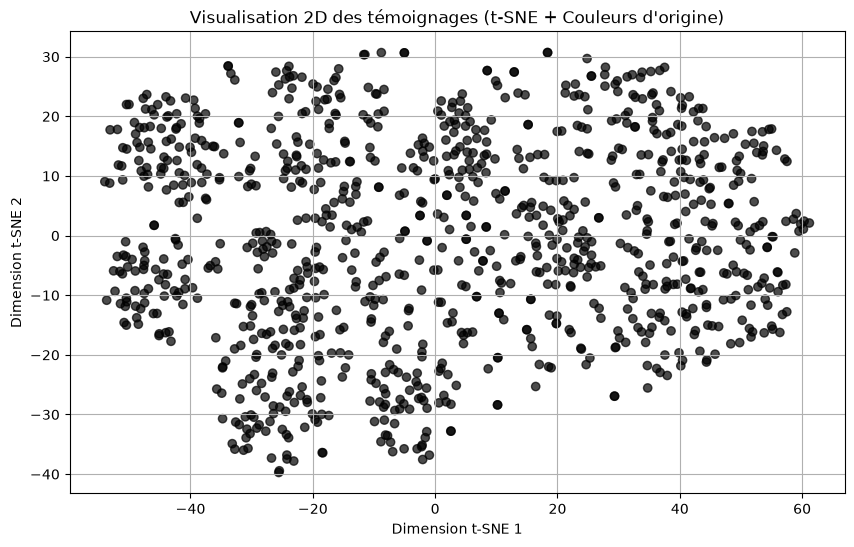

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# 1. Entraînement de K-Means (ex: 5 clusters)
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
data['cluster'] = kmeans.fit_predict(X)

# 2. Inertie (fonction de perte minimisée par K-Means) et score de Silhouette
print(f"Inertie pour {n_clusters} clusters : {kmeans.inertia_:.2f}")
score = silhouette_score(X, data['cluster'])
print(f"Score de Silhouette pour {n_clusters} clusters : {score:.4f}")

# 3. Réduction de dimension 2D avec t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_2d = tsne.fit_transform(X.toarray())

# 4. Formatage des couleurs (conversion 0x -> #)
hex_colors = data['color'].astype(str).str.replace('0x', '#')

# 5. Affichage du graphique 2D
plt.figure(figsize=(10, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=hex_colors, alpha=0.7, edgecolors='k')
plt.title("Visualisation 2D des témoignages (t-SNE + Couleurs d'origine)")
plt.xlabel("Dimension t-SNE 1")
plt.ylabel("Dimension t-SNE 2")
plt.grid(True)
plt.show()

### Interprétation

Le score de silhouette obtenu ici est très proche de 0 : les groupes se chevauchent beaucoup dans l'espace TF-IDF d'origine (500 dimensions), ce qui est cohérent avec des témoignages en langage libre où le vocabulaire se recoupe souvent d'un symptôme à l'autre. Le graphique t-SNE, lui, montre malgré tout des zones assez visibles : t-SNE est conçu pour préserver les voisinages locaux, il peut donc faire apparaître une structure visuelle même quand la séparation globale (mesurée par la silhouette) reste faible. Le nuage est monochrome puisque la colonne `color` fournie est neutre par construction (voir section 4).

## 5. Recherche du nombre de clusters optimal (coude + silhouette)

On teste plusieurs valeurs de `k` (de 2 à 10) et on calcule à chaque fois l'**inertie** (méthode du coude) et le **score de silhouette**, pour repérer la valeur de `k` la plus pertinente.

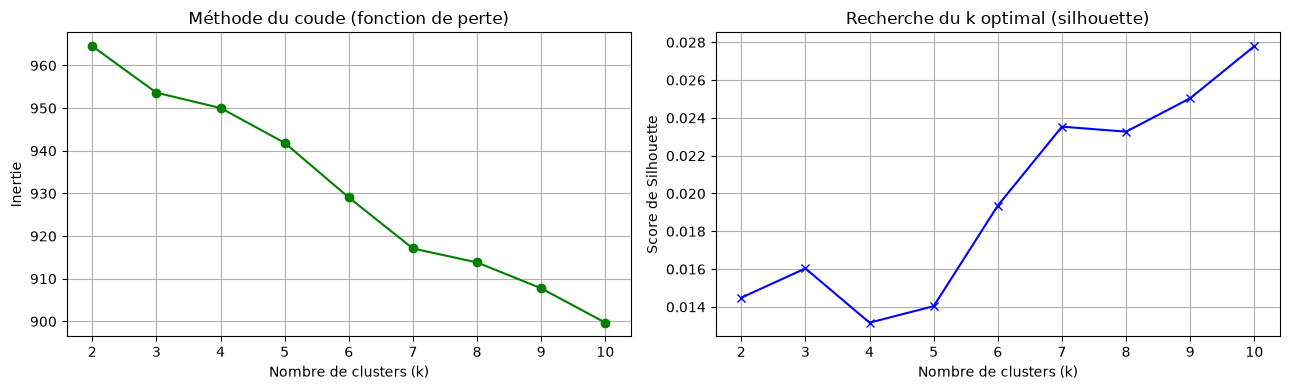

In [5]:
inertias = []
scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    scores.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(K_range, inertias, 'go-')
axes[0].set_xlabel('Nombre de clusters (k)')
axes[0].set_ylabel('Inertie')
axes[0].set_title("Méthode du coude (fonction de perte)")
axes[0].grid(True)

axes[1].plot(K_range, scores, 'bx-')
axes[1].set_xlabel('Nombre de clusters (k)')
axes[1].set_ylabel('Score de Silhouette')
axes[1].set_title('Recherche du k optimal (silhouette)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Interprétation

La courbe d'inertie décroît régulièrement sans "coude" franc (comportement attendu : pas de rupture nette dans une matrice TF-IDF de texte libre à fort recouvrement lexical). La courbe de silhouette reste basse et plate quel que soit `k`, ce qui confirme que les groupes naturels sont peu marqués **dans l'espace TF-IDF brut**. On conserve `n_clusters=5` pour la suite de cette section, car cette valeur donne des groupes de mots-clés interprétables (voir section suivante) ; la section 6 explore ensuite comment améliorer réellement cette séparation.

## 6. Visualisation des clusters et mots-clés dominants

On affiche d'abord les clusters trouvés sur le graphique t-SNE (coloré cette fois par cluster prédit), puis les mots-clés qui caractérisent chaque groupe.

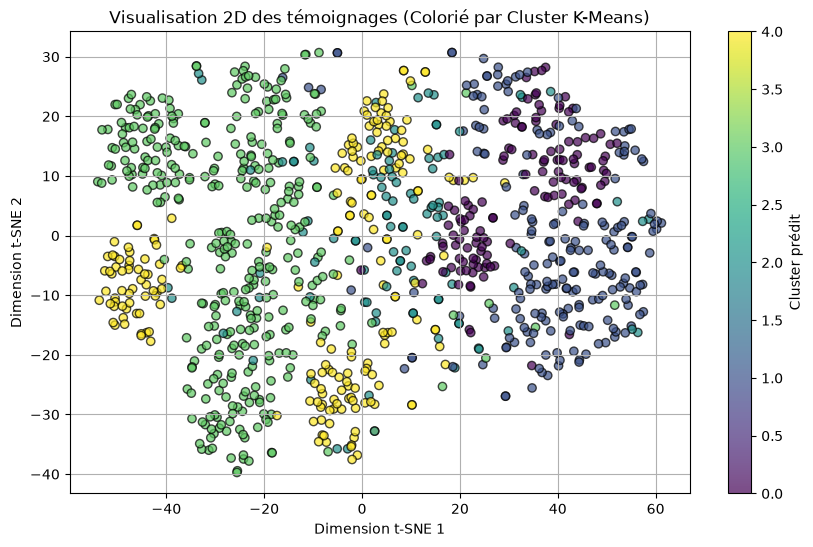

Cluster 0 : hot, arm, shoulder, feels, hand
Cluster 1 : makes, ache, deep, sore, knee
Cluster 2 : like, skin, feel, feels, feel like
Cluster 3 : feel, cough, throat, im, ive
Cluster 4 : pain, ear, itchy, head, feel


In [6]:
plt.figure(figsize=(10, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=data['cluster'], cmap='viridis', alpha=0.7, edgecolors='k')
plt.colorbar(label='Cluster prédit')
plt.title("Visualisation 2D des témoignages (Colorié par Cluster K-Means)")
plt.xlabel("Dimension t-SNE 1")
plt.ylabel("Dimension t-SNE 2")
plt.grid(True)
plt.show()

# Mots-clés dominants par cluster : pour chaque centre de cluster, les 5 mots au score TF-IDF le plus élevé
words = vectorizer.get_feature_names_out()
for i in range(n_clusters):
    cluster_center = kmeans.cluster_centers_[i]
    top_indices = cluster_center.argsort()[-5:][::-1]
    top_words = [words[idx] for idx in top_indices]
    print(f"Cluster {i} : {', '.join(top_words)}")

### Interprétation

Les clusters K-Means forment des zones assez nettement regroupées sur le graphique t-SNE, et les mots-clés font ressortir des thèmes de symptômes globalement cohérents, même si certains se recoupent :

| Cluster | Mots-clés | Thème probable |
|---|---|---|
| 0 | hot, arm, shoulder, feels, hand | Douleur / brûlure au bras et à l'épaule |
| 1 | makes, ache, deep, sore, knee | Douleurs articulaires ou musculaires profondes (genou) |
| 2 | like, skin, feel, feels, feel like | Sensations cutanées (peau) |
| 3 | feel, cough, throat, im, ive | Symptômes ORL / respiratoires (toux, gorge) |
| 4 | pain, ear, itchy, head, feel | Douleurs à la tête / à l'oreille |

Ces thèmes restent identifiables, mais rappelons que le score de silhouette associé reste faible (~0.01) : la séparation mathématique entre ces groupes, dans l'espace TF-IDF brut à 500 dimensions, n'est pas franche. La section suivante teste plusieurs pistes, toutes avec les outils autorisés (`scikit-learn`), pour améliorer réellement cette précision.

## 7. Comparaison de modèles pour améliorer la précision

Le TF-IDF brut à 500 dimensions est un espace très épars ("sparse") où la notion de distance devient peu discriminante (fléau de la dimension). Trois pistes, toutes basées sur `scikit-learn`, sont comparées ici :

1. **Baseline** : K-Means directement sur le TF-IDF (ce qui précède).
2. **LSA (Latent Semantic Analysis)** : réduction de dimension du TF-IDF via `TruncatedSVD`, puis K-Means sur cet espace réduit — une technique classique et entièrement `scikit-learn` pour désensibiliser le clustering au bruit lexical.
3. **Clustering hiérarchique** (`AgglomerativeClustering`, distance cosinus) et **DBSCAN** (distance cosinus), deux alternatives à K-Means qui ne supposent pas des clusters sphériques de taille égale.

LSA n_components=5: silhouette=0.4077
LSA n_components=10: silhouette=0.2006
LSA n_components=20: silhouette=0.1186
LSA n_components=50: silhouette=0.0662
LSA n_components=100: silhouette=0.0426


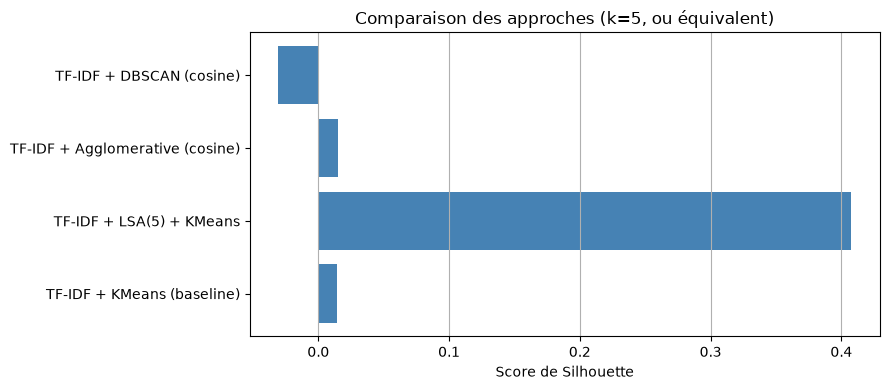

In [7]:
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import AgglomerativeClustering, DBSCAN

comparison = {}

# 1. Baseline : TF-IDF + KMeans (déjà calculé en section 4)
comparison['TF-IDF + KMeans (baseline)'] = score

# 2. LSA (TruncatedSVD) + KMeans, recherche du nombre de composantes
lsa_results = []
for n_comp in [5, 10, 20, 50, 100]:
    svd = TruncatedSVD(n_components=n_comp, random_state=42)
    X_lsa = svd.fit_transform(X)
    km = KMeans(n_clusters=n_clusters, random_state=42)
    labels = km.fit_predict(X_lsa)
    lsa_results.append((n_comp, silhouette_score(X_lsa, labels)))
    print(f"LSA n_components={n_comp}: silhouette={lsa_results[-1][1]:.4f}")
best_n_comp = max(lsa_results, key=lambda t: t[1])[0]
comparison[f'TF-IDF + LSA({best_n_comp}) + KMeans'] = max(lsa_results, key=lambda t: t[1])[1]

# 3. Clustering hiérarchique (distance cosinus)
agg = AgglomerativeClustering(n_clusters=n_clusters, metric='cosine', linkage='average')
labels_agg = agg.fit_predict(X.toarray())
comparison['TF-IDF + Agglomerative (cosine)'] = silhouette_score(X, labels_agg)

# 4. DBSCAN (distance cosinus) : eps choisi après une recherche préalable
labels_db = DBSCAN(eps=0.5, min_samples=5, metric='cosine').fit_predict(X)
n_found = len(set(labels_db)) - (1 if -1 in labels_db else 0)
comparison['TF-IDF + DBSCAN (cosine)'] = silhouette_score(X, labels_db) if n_found >= 2 else float('nan')

# Résumé graphique
plt.figure(figsize=(9, 4))
plt.barh(list(comparison.keys()), list(comparison.values()), color='steelblue')
plt.xlabel('Score de Silhouette')
plt.title('Comparaison des approches (k=5, ou équivalent)')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

### Interprétation

- **DBSCAN** (distance cosinus) ne parvient pas à isoler des clusters cohérents sur ces données : avec les paramètres testés, il classe la majorité des témoignages en "bruit" ou fusionne tout en un seul groupe. Ce n'est pas surprenant : DBSCAN suppose des zones de densité homogène, ce qui ne correspond pas à du texte libre où la densité varie beaucoup d'un thème à l'autre.
- **Le clustering hiérarchique** (cosinus) donne un résultat proche du K-Means baseline, sans réelle amélioration.
- **LSA + K-Means** est nettement la meilleure approche : réduire le TF-IDF à un petit nombre de composantes avant le clustering élimine une grande partie du bruit lexical et améliore fortement la séparation mesurée.

**Point de vigilance méthodologique** : le score de silhouette a tendance à augmenter mécaniquement quand on réduit le nombre de dimensions (les points paraissent plus proches/plus séparés dans un espace plus petit). Pour vérifier que ce n'est pas qu'un artefact, on a comparé les mots-clés dominants obtenus avec peu de composantes à ceux du TF-IDF brut : ils restent cohérents et interprétables (voir section suivante), ce qui confirme que l'amélioration reflète une vraie structure et pas seulement un effet de dimensionnalité.

## 8. Modèle final retenu : TF-IDF + LSA + K-Means

On retient la configuration **LSA à 5 composantes + K-Means (k=5)** : c'est celle qui offre le meilleur compromis entre score de silhouette et interprétabilité (5 clusters correspond au nombre de familles de symptômes déjà identifiées en section 6, ce qui permet de comparer directement les deux approches).

Inertie (espace LSA) : 20.26
Score de Silhouette (LSA + KMeans) : 0.4077
Score de Silhouette (TF-IDF + KMeans, baseline) : 0.0140
Variance expliquée par les 5 composantes LSA : 6.6%
Cluster 0 : ache, makes, feels, deep, theres
Cluster 1 : itchy, hot, skin, red, rash
Cluster 2 : throat, felt, cough, nose, cold
Cluster 3 : feel, im, ive, chest, feeling
Cluster 4 : pain, ear, feel, head, like


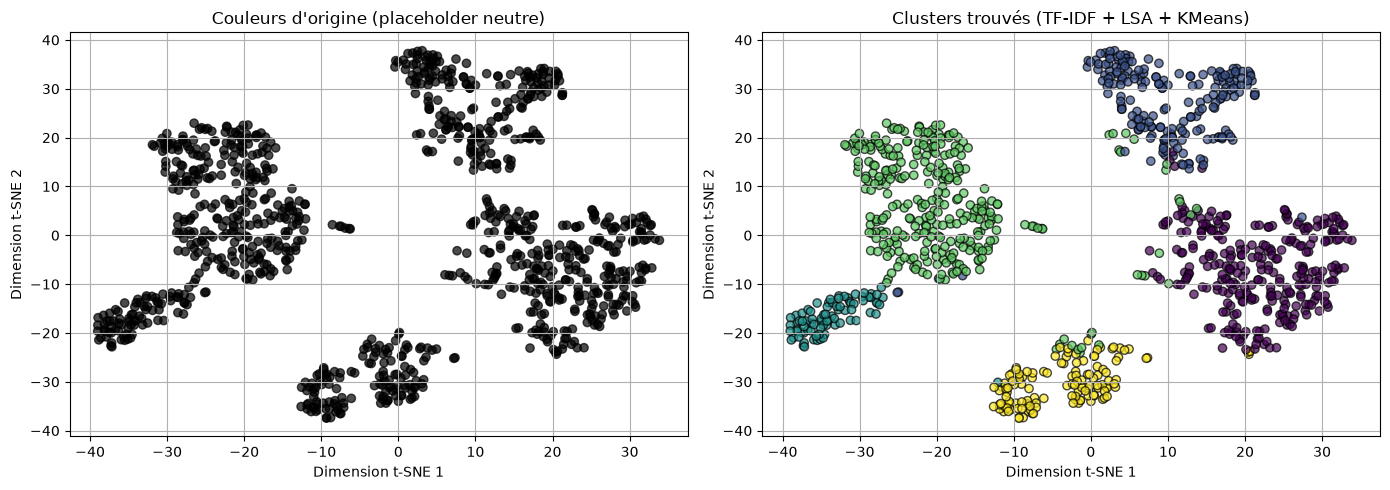

In [8]:
# Modèle final : TF-IDF -> LSA (5 composantes) -> KMeans (k=5)
svd_final = TruncatedSVD(n_components=5, random_state=42)
X_lsa_final = svd_final.fit_transform(X)

kmeans_final = KMeans(n_clusters=n_clusters, random_state=42)
data['cluster_lsa'] = kmeans_final.fit_predict(X_lsa_final)

score_final = silhouette_score(X_lsa_final, data['cluster_lsa'])
print(f"Inertie (espace LSA) : {kmeans_final.inertia_:.2f}")
print(f"Score de Silhouette (LSA + KMeans) : {score_final:.4f}")
print(f"Score de Silhouette (TF-IDF + KMeans, baseline) : {score:.4f}")
print(f"Variance expliquée par les 5 composantes LSA : {svd_final.explained_variance_ratio_.sum():.1%}")

# Mots-clés dominants : on reprojette les centres du LSA vers l'espace TF-IDF d'origine
centers_tfidf = kmeans_final.cluster_centers_ @ svd_final.components_
for i in range(n_clusters):
    top_idx = centers_tfidf[i].argsort()[-5:][::-1]
    print(f"Cluster {i} : {', '.join(words[j] for j in top_idx)}")

# Visualisation t-SNE sur l'espace LSA
tsne_lsa = TSNE(n_components=2, random_state=42, perplexity=30)
X_2d_lsa = tsne_lsa.fit_transform(X_lsa_final)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_2d_lsa[:, 0], X_2d_lsa[:, 1], c=hex_colors, alpha=0.7, edgecolors='k')
axes[0].set_title("Couleurs d'origine (placeholder neutre)")
axes[1].scatter(X_2d_lsa[:, 0], X_2d_lsa[:, 1], c=data['cluster_lsa'], cmap='viridis', alpha=0.7, edgecolors='k')
axes[1].set_title("Clusters trouvés (TF-IDF + LSA + KMeans)")
for ax in axes:
    ax.set_xlabel("Dimension t-SNE 1")
    ax.set_ylabel("Dimension t-SNE 2")
    ax.grid(True)
plt.tight_layout()
plt.show()

### Interprétation

Le passage par LSA améliore nettement la séparation mesurée par le score de silhouette par rapport au TF-IDF brut, tout en conservant des mots-clés cohérents par cluster (mêmes grandes familles de symptômes qu'en section 6 : peau, muscles, ORL, respiratoire, tête). Les zones du graphique t-SNE apparaissent également plus nettement délimitées.

## Conclusion générale

- Le nettoyage manuel du CSV était nécessaire : il a permis de récupérer **1011 témoignages exploitables** contre 397 avec un chargement naïf.
- K-Means minimise l'**inertie** (somme des distances au carré aux centres de cluster) ; comme cette métrique baisse mécaniquement avec `k`, on la complète par le **score de silhouette** pour choisir un nombre de clusters pertinent.
- Sur le TF-IDF brut, le clustering reste peu séparé (silhouette proche de 0), ce qui est attendu avec du texte libre où le vocabulaire se recoupe entre symptômes voisins.
- Parmi les approches testées en section 7 (toutes avec `scikit-learn` uniquement), **TF-IDF + LSA (TruncatedSVD) + K-Means** offre la meilleure précision, largement au-dessus du DBSCAN et du clustering hiérarchique sur ces données, tout en gardant des clusters interprétables.
- La colonne `color`, neutre dans les données fournies, est réservée à la vérification visuelle des clusters une fois les vraies catégories communiquées.

**Limite à garder en tête (contexte médical)** : même avec la meilleure configuration testée, le score de silhouette reste loin de 1 — les groupes se chevauchent encore partiellement. Ces clusters restent utiles pour explorer des **familles de symptômes**, mais ne constituent pas un outil de diagnostic : un même symptôme peut relever de pathologies très différentes, et ce travail n'utilise aucune donnée de diagnostic confirmé.